In [29]:
#Setup of the Code, importing the necessary libraries and setting up the data directory path.
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("..") / "data"

In [30]:
# Import both LG datasets from the local data folder.
LG_DIR = DATA_DIR / "01_LG_Electronics_Appliances"

df_reviews = pd.read_csv(LG_DIR / "appliance_brand_reviews.csv")
df_behavior = pd.read_csv(LG_DIR / "electronics_market_behavior.csv")

print("Reviews:", df_reviews.shape)
print("Market behavior:", df_behavior.shape)


Reviews: (20004, 14)
Market behavior: (649605, 8)


In [31]:
# 1. Prepare the data
# Make a working copy of the events and prepare the dates for the analysis.
import matplotlib.pyplot as plt
from IPython.display import display

events = df_behavior.copy()
events['event_time'] = pd.to_datetime(events['event_time'], utc=True)
key = ['user_id', 'session_id', 'product_id']


In [32]:
# 2. Check data quality
# Look for missing values, duplicates and inconsistent product information.
print('Rows and columns:', events.shape)
print('Date range:', events['event_time'].min(), 'to', events['event_time'].max())
display(events.isna().sum().rename('missing_values').to_frame())
duplicate_rows = int(df_behavior.duplicated().sum())
print('Exact duplicate rows:', duplicate_rows)
print('Non-positive prices:', (events['price'] <= 0).sum())
print('Event types:', events['event_type'].unique())

product_mapping = events.groupby('product_id')[['brand', 'product_category']].nunique()
display(product_mapping.max().rename('maximum_values_per_product').to_frame())
session_users = events.groupby('session_id')['user_id'].nunique()
print('Session IDs shared by multiple users:', (session_users > 1).sum())
assert events.notna().all().all()
assert np.isfinite(events['price']).all() and (events['price'] > 0).all()
assert events['event_type'].isin(['view', 'cart', 'purchase']).all()
assert (product_mapping == 1).all().all()


Rows and columns: (649605, 8)
Date range: 2019-10-01 00:06:07+00:00 to 2019-11-30 23:56:30+00:00


,missing_values
event_time,0
event_type,0
user_id,0
session_id,0
product_id,0
product_category,0
brand,0
price,0


Exact duplicate rows: 1247
Non-positive prices: 0
Event types: <StringArray>
['view', 'purchase', 'cart']
Length: 3, dtype: str


,maximum_values_per_product
brand,1
product_category,1


Session IDs shared by multiple users: 4


In [33]:
# 3. Select the events we need
# Keep October-November 2019, TVs, LG and Samsung. Show how many records remain.
period_events = events[(events['event_time'] >= '2019-10-01') &
                       (events['event_time'] < '2019-12-01')].copy()
tv_events = period_events[period_events['product_category'] == 'tv'].copy()
tv = tv_events[tv_events['brand'].isin(['lg', 'samsung'])].copy()
audit = pd.DataFrame({
    'stage': ['Raw file', 'October-November', 'TV category', 'LG/Samsung TVs'],
    'event_rows': [len(events), len(period_events), len(tv_events), len(tv)],
    'keys': [len(events[key].drop_duplicates()), len(period_events[key].drop_duplicates()),
             len(tv_events[key].drop_duplicates()), len(tv[key].drop_duplicates())],
    'users': [events['user_id'].nunique(), period_events['user_id'].nunique(),
              tv_events['user_id'].nunique(), tv['user_id'].nunique()],
    'products': [events['product_id'].nunique(), period_events['product_id'].nunique(),
                 tv_events['product_id'].nunique(), tv['product_id'].nunique()],
    'purchase_events': [(events['event_type'] == 'purchase').sum(),
                        (period_events['event_type'] == 'purchase').sum(),
                        (tv_events['event_type'] == 'purchase').sum(),
                        (tv['event_type'] == 'purchase').sum()]
})
audit['events_excluded'] = audit['event_rows'].shift(1) - audit['event_rows']
audit.loc[0, 'events_excluded'] = 0
display(audit)


,stage,event_rows,keys,users,products,purchase_events,events_excluded
0,Raw file,649605,363382,138863,1613,10368,0.0000
1,October-November,649605,363382,138863,1613,10368,0.0000
2,TV category,212303,115750,50373,290,3785,"437,302.0000"
3,LG/Samsung TVs,135411,74739,35885,196,2331,"76,892.0000"


In [34]:
# 4. Find the important events
# For each user-session-product, find the first view, the first later cart and the last purchase.
views = tv[tv['event_type'] == 'view'].copy()
first_views = views.sort_values('event_time', kind='stable').drop_duplicates(key)
first_views = first_views[key + ['brand', 'event_time', 'price']]
first_views = first_views.rename(columns={'event_time': 'first_view', 'price': 'initial_price'})

purchases = tv[tv['event_type'] == 'purchase'].copy()
last_purchases = purchases.groupby(key)['event_time'].max().reset_index()
last_purchases = last_purchases.rename(columns={'event_time': 'last_purchase'})

carts = tv[tv['event_type'] == 'cart'].copy()
carts = carts.merge(first_views[key + ['first_view']], on=key)
carts = carts[carts['event_time'] > carts['first_view']]
first_carts = carts.groupby(key)['event_time'].min().reset_index()
first_carts = first_carts.rename(columns={'event_time': 'first_cart'})


In [35]:
# 5. Create the analytical table
# Each row is one viewed user-session-product. Y=1 means a purchase strictly after its first view.
# Y=0 means no qualifying purchase was observed in this row.
baseline_full = first_views.merge(last_purchases, on=key, how='left')
baseline_full = baseline_full.merge(first_carts, on=key, how='left')
baseline_full['Y'] = (baseline_full['last_purchase'] > baseline_full['first_view']).astype(int)
baseline_full['has_cart'] = baseline_full['first_cart'].notna()
baseline_full['purchase_after_cart'] = baseline_full['last_purchase'] > baseline_full['first_cart']
baseline_full['purchase_without_cart_path'] = (baseline_full['Y'] == 1) & ~baseline_full['purchase_after_cart']
baseline_full['month'] = baseline_full['first_view'].dt.strftime('%Y-%m')

assert not baseline_full.duplicated(key).any()
assert baseline_full['Y'].isin([0, 1]).all()
print('Eligible considerations:', len(baseline_full))
print('Purchase outcomes:', baseline_full['Y'].sum())
eligible_events = tv.merge(baseline_full[key], on=key)
display(pd.DataFrame({
    'stage': ['Keys containing at least one view'], 'event_rows': [len(eligible_events)],
    'keys': [len(baseline_full)], 'users': [baseline_full['user_id'].nunique()],
    'products': [baseline_full['product_id'].nunique()],
    'purchase_events': [(eligible_events['event_type'] == 'purchase').sum()],
    'purchase_outcomes': [baseline_full['Y'].sum()],
    'events_excluded': [len(tv) - len(eligible_events)]
}))


Eligible considerations: 74712
Purchase outcomes: 2150


,stage,event_rows,keys,users,products,purchase_events,purchase_outcomes,events_excluded
0,Keys containing at least one view,135368,74712,35871,196,2312,2150,43


In [36]:
# 6. Check the effect of duplicates
# Verify that removing exact copies does not change the events used to calculate our KPIs.
first_views_dedup = views.drop_duplicates().sort_values('event_time', kind='stable').drop_duplicates(key)
first_views_dedup = first_views_dedup[key + ['brand', 'event_time', 'price']]
first_views_dedup = first_views_dedup.rename(columns={'event_time': 'first_view', 'price': 'initial_price'})
pd.testing.assert_frame_equal(first_views.reset_index(drop=True), first_views_dedup.reset_index(drop=True))
assert purchases.groupby(key)['event_time'].max().equals(purchases.drop_duplicates().groupby(key)['event_time'].max())
assert carts.groupby(key)['event_time'].min().equals(carts.drop_duplicates().groupby(key)['event_time'].min())
print('Duplicate removal leaves first views, first eligible carts and last purchases unchanged.')


Duplicate removal leaves first views, first eligible carts and last purchases unchanged.


In [37]:
# 7. Check event timing
# Count purchases without an earlier view and events at the same time. Flag views on the final day.
purchase_timing = purchases.merge(first_views[key + ['first_view']], on=key, how='left')
print('Raw TV purchase events:', len(purchase_timing))
print('No view in the key:', purchase_timing['first_view'].isna().sum())
print('Purchase before first view:', (purchase_timing['event_time'] < purchase_timing['first_view']).sum())
print('Purchase at first view:', (purchase_timing['event_time'] == purchase_timing['first_view']).sum())
print('Purchase strictly after first view:', (purchase_timing['event_time'] > purchase_timing['first_view']).sum())
time_key = key + ['event_time']
same_time_views = purchases.merge(views[time_key].drop_duplicates(), on=time_key)
all_carts = tv[tv['event_type'] == 'cart']
same_time_carts = purchases.merge(all_carts[time_key].drop_duplicates(), on=time_key)
print('Purchase events at any view timestamp:', len(same_time_views))
print('Purchase events at any cart timestamp:', len(same_time_carts))

final_day = baseline_full[baseline_full['first_view'] >= '2019-11-30']
display(final_day.groupby('brand').agg(considerations=('Y', 'size'), purchases=('Y', 'sum')))


Raw TV purchase events: 2331
No view in the key: 19
Purchase before first view: 14
Purchase at first view: 0
Purchase strictly after first view: 2298
Purchase events at any view timestamp: 0
Purchase events at any cart timestamp: 0


,considerations,purchases
brand,,
lg,372,15
samsung,742,23


In [38]:
# 8. Calculate overall KPIs
# Divide purchases and carts by all considerations. For cart-to-purchase, divide by eligible carts.
# A qualifying cart must occur after the first view, and its purchase must occur strictly later.
overall_kpis = baseline_full.groupby('brand').agg(
    considerations=('Y', 'size'), purchases=('Y', 'sum'),
    carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum'),
    purchases_without_cart_path=('purchase_without_cart_path', 'sum'),
    users=('user_id', 'nunique'), products=('product_id', 'nunique'))
overall_kpis['view_to_purchase_pct'] = 100 * overall_kpis['purchases'] / overall_kpis['considerations']
overall_kpis['view_to_cart_pct'] = 100 * overall_kpis['carts'] / overall_kpis['considerations']
overall_kpis['cart_to_purchase_pct'] = 100 * overall_kpis['purchases_after_cart'] / overall_kpis['carts'].replace(0, np.nan)
display(overall_kpis)
assert (overall_kpis['purchases'] == overall_kpis['purchases_after_cart'] + overall_kpis['purchases_without_cart_path']).all()
raw_gap_pp = overall_kpis.loc['lg', 'view_to_purchase_pct'] - overall_kpis.loc['samsung', 'view_to_purchase_pct']
print('Raw LG-minus-Samsung gap (percentage points):', round(raw_gap_pp, 4))


,considerations,purchases,carts,purchases_after_cart,purchases_without_cart_path,users,products,view_to_purchase_pct,view_to_cart_pct,cart_to_purchase_pct
brand,,,,,,,,,,
lg,22213,505,1073,374,131,12908,105,2.2734,4.8305,34.8555
samsung,52499,1645,3311,1330,315,29327,91,3.1334,6.3068,40.1691


Raw LG-minus-Samsung gap (percentage points): -0.8599


In [ ]:
# 9. Calculate monthly KPIs
# Repeat the calculations for October and November, using the month of the first view.
monthly_kpis = baseline_full.groupby(['brand', 'month']).agg(
    considerations=('Y', 'size'), purchases=('Y', 'sum'),
    carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum'),
    users=('user_id', 'nunique'), products=('product_id', 'nunique'))
monthly_kpis['view_to_purchase_pct'] = 100 * monthly_kpis['purchases'] / monthly_kpis['considerations']
monthly_kpis['view_to_cart_pct'] = 100 * monthly_kpis['carts'] / monthly_kpis['considerations']
monthly_kpis['cart_to_purchase_pct'] = 100 * monthly_kpis['purchases_after_cart'] / monthly_kpis['carts'].replace(0, np.nan)
monthly_kpis['share_of_brand_rows_pct'] = 100 * monthly_kpis['considerations'] / monthly_kpis.groupby('brand')['considerations'].transform('sum')
display(monthly_kpis)
counts = ['considerations', 'purchases', 'carts', 'purchases_after_cart']
assert monthly_kpis.groupby('brand')[counts].sum().equals(overall_kpis[counts])
monthly_rates = monthly_kpis['view_to_purchase_pct'].unstack('brand')
monthly_rates['LG_minus_Samsung_pp'] = monthly_rates['lg'] - monthly_rates['samsung']
display(monthly_rates)


In [40]:
# 10. Compare with the reference numbers
# Check our calculated results against the session plan. Investigate differences instead of changing the results.
reference = pd.DataFrame({
    'brand': ['lg', 'samsung'], 'considerations': [22213, 52499],
    'purchases': [505, 1645], 'products': [105, 91],
    'view_to_purchase_pct': [2.27, 3.13], 'view_to_cart_pct': [4.83, 6.31],
    'cart_to_purchase_pct': [34.86, 40.17]}).set_index('brand')
actual = overall_kpis[reference.columns].round(2)
reference_check = actual.eq(reference)
display(reference_check)
print('All reference counts and rounded rates match:', reference_check.all().all())


,considerations,purchases,products,view_to_purchase_pct,view_to_cart_pct,cart_to_purchase_pct
brand,,,,,,
lg,True,True,True,True,True,True
samsung,True,True,True,True,True,True


All reference counts and rounded rates match: True


,min,p01,p05,p25,median,p75,p95,p99,max
brand,,,,,,,,,
lg,231.4100,282.6300,295.3500,390.8600,460.8400,666.2700,"1,413.6300","2,547.7500","2,574.0400"
samsung,169.6300,261.7300,288.0400,381.7400,493.9600,635.2500,"1,415.7100","2,573.7900","2,574.0400"


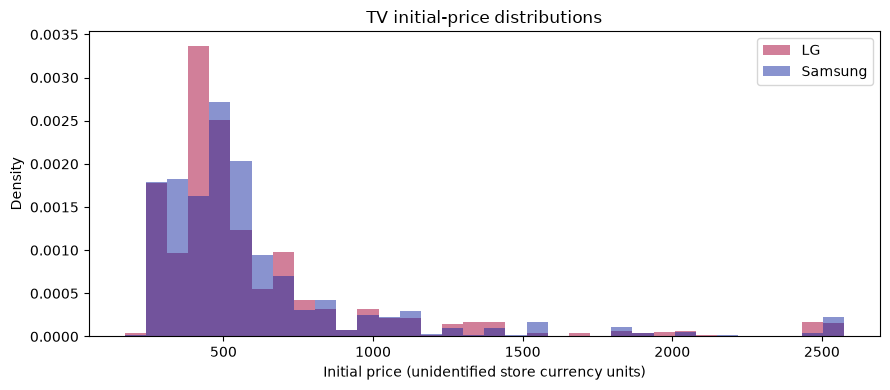

In [41]:
# 11. Compare prices
# Show price quantiles and distributions. Normalised histograms compare shapes despite different sample sizes.
# No price filter is applied: we will decide after inspecting the graphs and quantiles.
quantiles = baseline_full.groupby('brand')['initial_price'].quantile([0, .01, .05, .25, .5, .75, .95, .99, 1]).unstack()
quantiles.columns = ['min', 'p01', 'p05', 'p25', 'median', 'p75', 'p95', 'p99', 'max']
display(quantiles)
lg_prices = baseline_full.loc[baseline_full['brand'] == 'lg', 'initial_price']
samsung_prices = baseline_full.loc[baseline_full['brand'] == 'samsung', 'initial_price']
bins = np.linspace(baseline_full['initial_price'].min(), baseline_full['initial_price'].max(), 35)
plt.figure(figsize=(9, 4))
plt.hist(lg_prices, bins=bins, density=True, alpha=.5, label='LG', color='#A50034')
plt.hist(samsung_prices, bins=bins, density=True, alpha=.5, label='Samsung', color='#1428A0')
plt.xlabel('Initial price (unidentified store currency units)')
plt.ylabel('Density')
plt.title('TV initial-price distributions')
plt.legend()
plt.tight_layout()
plt.show()


In [42]:
# 12. Check product concentration
# Rank products by considerations and purchases. Calculate how much activity comes from the top products.
products = baseline_full.groupby(['brand', 'product_id']).agg(
    considerations=('Y', 'size'), purchases=('Y', 'sum')).reset_index()
products['conversion_pct'] = 100 * products['purchases'] / products['considerations']
most_viewed = products.sort_values(['brand', 'considerations', 'product_id'], ascending=[True, False, True])
most_purchased = products.sort_values(['brand', 'purchases', 'product_id'], ascending=[True, False, True])
display(most_viewed.groupby('brand').head(5))
display(most_purchased.groupby('brand').head(5))
concentration_tables = []
for number in [1, 5, 10]:
    top = most_viewed.groupby('brand').head(number)
    shares = top.groupby('brand')[['considerations', 'purchases']].sum()
    shares['share_of_brand_rows_pct'] = 100 * shares['considerations'] / overall_kpis['considerations']
    shares['share_of_brand_purchases_pct'] = 100 * shares['purchases'] / overall_kpis['purchases']
    shares['top_n'] = number
    concentration_tables.append(shares.reset_index())
product_concentration = pd.concat(concentration_tables, ignore_index=True)
display(product_concentration)
top5 = product_concentration[product_concentration['top_n'] == 5].set_index('brand')
print('Top-five references (LG 42.3%, Samsung 52.4%):')
display(top5['share_of_brand_rows_pct'].round(1))


,brand,product_id,considerations,purchases,conversion_pct
92,lg,P000640,2723,64,2.3503
34,lg,P000499,2416,74,3.0629
12,lg,P000463,1635,29,1.7737
26,lg,P000478,1510,51,3.3775
80,lg,P000617,1114,29,2.6032
136,samsung,P000507,9106,459,5.0406
145,samsung,P000554,6865,212,3.0881
139,samsung,P000517,4394,132,3.0041
170,samsung,P000581,4110,151,3.6740
146,samsung,P000555,3025,82,2.7107


,brand,product_id,considerations,purchases,conversion_pct
34,lg,P000499,2416,74,3.0629
92,lg,P000640,2723,64,2.3503
26,lg,P000478,1510,51,3.3775
38,lg,P000513,1023,33,3.2258
77,lg,P000614,1011,33,3.2641
136,samsung,P000507,9106,459,5.0406
145,samsung,P000554,6865,212,3.0881
170,samsung,P000581,4110,151,3.6740
139,samsung,P000517,4394,132,3.0041
142,samsung,P000541,2850,109,3.8246


,brand,considerations,purchases,share_of_brand_rows_pct,share_of_brand_purchases_pct,top_n
0,lg,2723,64,12.2586,12.6733,1
1,samsung,9106,459,17.3451,27.9027,1
2,lg,9398,247,42.3086,48.9109,5
3,samsung,27500,1036,52.3820,62.9787,5
4,lg,13226,351,59.5417,69.5050,10
5,samsung,37168,1355,70.7975,82.3708,10


Top-five references (LG 42.3%, Samsung 52.4%):


brand
lg        42.3000
samsung   52.4000
Name: share_of_brand_rows_pct, dtype: float64

In [43]:
# 13. Check user concentration
# Count repeated users and measure how much activity comes from the most active users.
users = baseline_full.groupby('user_id').agg(
    considerations=('Y', 'size'), sessions=('session_id', 'nunique'),
    brands_viewed=('brand', 'nunique'), products_viewed=('product_id', 'nunique'),
    purchases=('Y', 'sum'))
display(users.describe(percentiles=[.5, .9, .95, .99]))
repeated_users = users[users['considerations'] > 1]
print('Distinct users:', len(users))
print('Users with multiple consideration rows:', len(repeated_users))
print('Rows from repeated users:', repeated_users['considerations'].sum())
print('Share of rows from repeated users (%):', 100 * repeated_users['considerations'].sum() / len(baseline_full))
print('Users considering both brands:', (users['brands_viewed'] == 2).sum())
active_users = users.sort_values('considerations', ascending=False)
top_1_percent = active_users.head(int(np.ceil(len(users) * .01)))
print('Share of rows from the top 1% of users (%):', 100 * top_1_percent['considerations'].sum() / len(baseline_full))
print('Share of rows from the top 10 users (%):', 100 * active_users.head(10)['considerations'].sum() / len(baseline_full))


,considerations,sessions,brands_viewed,products_viewed,purchases
count,"35,871.0000","35,871.0000","35,871.0000","35,871.0000","35,871.0000"
mean,2.0828,1.1260,1.1774,2.0050,0.0599
std,2.0806,0.5652,0.3820,1.8891,0.2698
min,1.0000,1.0000,1.0000,1.0000,0.0000
50%,1.0000,1.0000,1.0000,1.0000,0.0000
90%,4.0000,1.0000,2.0000,4.0000,0.0000
95%,6.0000,2.0000,2.0000,5.0000,1.0000
99%,10.0000,3.0000,2.0000,10.0000,1.0000
max,51.0000,30.0000,2.0000,33.0000,11.0000


Distinct users: 35871
Users with multiple consideration rows: 15561
Rows from repeated users: 54402
Share of rows from repeated users (%): 72.81561194988757
Users considering both brands: 6364
Share of rows from the top 1% of users (%): 7.099261162865403
Share of rows from the top 10 users (%): 0.4684655744726416


In [44]:
# 14. Compare a sample without the top products
# Remove the most-considered product for each brand and recalculate the raw KPIs. Keep the baseline intact.
removed_products = most_viewed.groupby('brand').head(1)
display(removed_products)
exclude_top_viewed = baseline_full[~baseline_full['product_id'].isin(removed_products['product_id'])].copy()
comparison_data = pd.concat([
    baseline_full.assign(sample='baseline_full'),
    exclude_top_viewed.assign(sample='exclude_top_viewed')])
sample_kpis = comparison_data.groupby(['sample', 'brand']).agg(
    considerations=('Y', 'size'), purchases=('Y', 'sum'), carts=('has_cart', 'sum'),
    purchases_after_cart=('purchase_after_cart', 'sum'))
sample_kpis['view_to_purchase_pct'] = 100 * sample_kpis['purchases'] / sample_kpis['considerations']
sample_kpis['view_to_cart_pct'] = 100 * sample_kpis['carts'] / sample_kpis['considerations']
sample_kpis['cart_to_purchase_pct'] = 100 * sample_kpis['purchases_after_cart'] / sample_kpis['carts'].replace(0, np.nan)
display(sample_kpis)
sample_gaps = sample_kpis['view_to_purchase_pct'].unstack('brand')
sample_gaps['raw_LG_minus_Samsung_pp'] = sample_gaps['lg'] - sample_gaps['samsung']
display(sample_gaps)


,brand,product_id,considerations,purchases,conversion_pct
92,lg,P000640,2723,64,2.3503
136,samsung,P000507,9106,459,5.0406


considerations  purchases  carts  purchases_after_cart  view_to_purchase_pct  view_to_cart_pct  cart_to_purchase_pct
sample             brand                                                                                                                        
baseline_full      lg                22213        505   1073                   374                2.2734            4.8305               34.8555
                   samsung           52499       1645   3311                  1330                3.1334            6.3068               40.1691
exclude_top_viewed lg                19490        441    905                   315                2.2627            4.6434               34.8066
                   samsung           43393       1186   2436                   946                2.7332            5.6138               38.8342

brand,lg,samsung,raw_LG_minus_Samsung_pp
sample,,,
baseline_full,2.2734,3.1334,-0.8599
exclude_top_viewed,2.2627,2.7332,-0.4705


In [48]:
# 14b. Compare a sample of users who considered both brands
# Keep shoppers with at least one LG and one Samsung consideration, so both brand rates use the same people.
brands_per_user = baseline_full.groupby('user_id')['brand'].nunique()
dual_brand_ids = brands_per_user[brands_per_user == 2].index
dual_brand_users = baseline_full[baseline_full['user_id'].isin(dual_brand_ids)].copy()

# Users whose outcome varies (at least one Y=1 and one Y=0 row) are the ones a user fixed-effects logit can use.
y_varies = dual_brand_users.groupby('user_id')['Y'].nunique() == 2
usable_ids = y_varies[y_varies].index
usable_rows = dual_brand_users['user_id'].isin(usable_ids)

dual_brand_check = pd.DataFrame({
    'check': ['Users in baseline',
              'Users who considered both brands',
              'Consideration rows from dual-brand users',
              'Share of baseline rows (%)',
              'Purchase outcomes from dual-brand users',
              'Dual-brand users with both Y=0 and Y=1 rows',
              'Rows from those users',
              'Purchase outcomes from those users'],
    'value': [baseline_full['user_id'].nunique(),
              len(dual_brand_ids),
              len(dual_brand_users),
              100 * len(dual_brand_users) / len(baseline_full),
              dual_brand_users['Y'].sum(),
              y_varies.sum(),
              usable_rows.sum(),
              dual_brand_users.loc[usable_rows, 'Y'].sum()]
})
display(dual_brand_check)

dual_brand_kpis = dual_brand_users.groupby('brand').agg(
    considerations=('Y', 'size'), purchases=('Y', 'sum'), carts=('has_cart', 'sum'),
    purchases_after_cart=('purchase_after_cart', 'sum'), users=('user_id', 'nunique'))
dual_brand_kpis['view_to_purchase_pct'] = 100 * dual_brand_kpis['purchases'] / dual_brand_kpis['considerations']
dual_brand_kpis['view_to_cart_pct'] = 100 * dual_brand_kpis['carts'] / dual_brand_kpis['considerations']
dual_brand_kpis['cart_to_purchase_pct'] = 100 * dual_brand_kpis['purchases_after_cart'] / dual_brand_kpis['carts'].replace(0, np.nan)
display(dual_brand_kpis)

dual_brand_gap_pp = dual_brand_kpis.loc['lg', 'view_to_purchase_pct'] - dual_brand_kpis.loc['samsung', 'view_to_purchase_pct']
sample_gaps.loc['dual_brand_users'] = [dual_brand_kpis.loc['lg', 'view_to_purchase_pct'],
                                       dual_brand_kpis.loc['samsung', 'view_to_purchase_pct'],
                                       dual_brand_gap_pp]
display(sample_gaps)
print('Dual-brand users, raw LG-minus-Samsung gap (percentage points):', round(dual_brand_gap_pp, 4))
print('Change from baseline gap (percentage points):', round(dual_brand_gap_pp - raw_gap_pp, 4))

,check,value
0,Users in baseline,"35,871.0000"
1,Users who considered both brands,"6,364.0000"
2,Consideration rows from dual-brand users,"28,027.0000"
3,Share of baseline rows (%),37.5134
4,Purchase outcomes from dual-brand users,394.0000
5,Dual-brand users with both Y=0 and Y=1 rows,332.0000
6,Rows from those users,"1,697.0000"
7,Purchase outcomes from those users,370.0000


,considerations,purchases,carts,purchases_after_cart,users,view_to_purchase_pct,view_to_cart_pct,cart_to_purchase_pct
brand,,,,,,,,
lg,12194,169,440,137,6364,1.3859,3.6083,31.1364
samsung,15833,225,578,175,6364,1.4211,3.6506,30.2768


brand,lg,samsung,raw_LG_minus_Samsung_pp
sample,,,
baseline_full,2.2734,3.1334,-0.8599
exclude_top_viewed,2.2627,2.7332,-0.4705
dual_brand_users,1.3859,1.4211,-0.0352


Dual-brand users, raw LG-minus-Samsung gap (percentage points): -0.0352
Change from baseline gap (percentage points): 0.8248


In [ ]:
# 15. Inspect a few event sequences
# Look at real examples to check that the calculations follow the events correctly.
# Clear this cell's outputs before committing, because they display raw event rows.
repeated_views = views.groupby(key).size().reset_index(name='view_events')
repeated_views = repeated_views[repeated_views['view_events'] > 1]
examples = pd.concat([
    baseline_full[(baseline_full['Y'] == 1) & ~baseline_full['has_cart']].head(1).assign(pattern='View then purchase, no eligible cart'),
    baseline_full[baseline_full['purchase_after_cart']].head(1).assign(pattern='View then cart then purchase'),
    repeated_views.head(1).assign(pattern='Repeated views'),
    baseline_full[baseline_full['has_cart'] & ~baseline_full['purchase_after_cart']].head(1).assign(pattern='Cart without later purchase'),
    baseline_full[baseline_full['purchase_without_cart_path']].head(1).assign(pattern='Purchase without qualifying cart path'),
    same_time_views.head(1).assign(pattern='Equal-time view/purchase'),
    same_time_carts.head(1).assign(pattern='Equal-time cart/purchase')], ignore_index=True)
for _, example in examples.iterrows():
    sequence = tv[(tv['user_id'] == example['user_id']) &
                  (tv['session_id'] == example['session_id']) &
                  (tv['product_id'] == example['product_id'])]
    sequence = sequence.sort_values('event_time', kind='stable')
    print(example['pattern'], '| Total events:', len(sequence))
    display(sequence[['event_time', 'event_type', 'brand', 'price']].head(30))


In [46]:
# 16. Summarise the checks
# Discuss the purchase definition, price/product comparability and repeated users/products with the tutor.
# The next session covers Logit. This session focuses on descriptive checks.
print('Cohort and KPI references match:', reference_check.all().all())
print('Raw duplicate reference matches:', duplicate_rows == 1247)
print('Shared-session reference matches:', (session_users > 1).sum() == 4)
print('No price filter has been applied.')


Cohort and KPI references match: True
Raw duplicate reference matches: True
Shared-session reference matches: True
No price filter has been applied.
